## Assignment no 11

## Decision Tree Classification – Heart Disease Prediction


 1: Import required libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


2 Load your dataset

In [2]:
file_path = "heart_disease.csv"

df = pd.read_excel(
    file_path,
    sheet_name="Heart_disease",
    engine="openpyxl"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (908, 13)


,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
0,63,Male,typical angina,145,233,True,lv hypertrophy,150,False,2.3,downsloping,fixed defect,0
1,41,Male,atypical angina,135,203,False,normal,132,False,0.0,flat,fixed defect,0
2,57,Male,asymptomatic,140,192,False,normal,148,False,0.4,flat,fixed defect,0
3,52,Male,typical angina,118,186,False,lv hypertrophy,190,False,0.0,flat,fixed defect,0
4,57,Male,asymptomatic,110,201,False,normal,126,True,1.5,flat,fixed defect,0


3. Clean and inspect the dataset

In [3]:
# Clean column names
df.columns = df.columns.str.strip()

# Remove extra spaces from text values
for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.strip()

# Convert common missing-value marker to actual missing values
df = df.replace(r"^\?$", np.nan, regex=True)

print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all"))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 908 entries, 0 to 907
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       908 non-null    int64  
 1   sex       908 non-null    object 
 2   cp        908 non-null    object 
 3   trestbps  908 non-null    int64  
 4   chol      908 non-null    int64  
 5   fbs       908 non-null    bool   
 6   restecg   908 non-null    object 
 7   thalch    908 non-null    int64  
 8   exang     55 non-null     object 
 9   oldpeak   846 non-null    float64
 10  slope     908 non-null    object 
 11  thal      908 non-null    object 
 12  num       908 non-null    int64  
dtypes: bool(1), float64(1), int64(5), object(6)
memory usage: 86.1+ KB

Statistical summary:


,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
count,908.000000,908,908,908.000000,908.000000,908,908,908.000000,55,846.000000,908,908,908.000000
unique,NaN,2,4,NaN,NaN,2,3,NaN,2,NaN,3,3,NaN
top,NaN,Male,asymptomatic,NaN,NaN,False,normal,NaN,TURE,NaN,flat,reversable defect,NaN
freq,NaN,718,495,NaN,NaN,723,542,NaN,36,NaN,453,372,NaN
mean,53.791850,NaN,NaN,133.430617,201.484581,NaN,NaN,135.957048,NaN,0.891253,NaN,NaN,1.008811
std,9.158031,NaN,NaN,20.401608,112.097949,NaN,NaN,26.804929,NaN,1.093875,NaN,NaN,1.144436
min,29.000000,NaN,NaN,0.000000,0.000000,NaN,NaN,60.000000,NaN,-2.600000,NaN,NaN,0.000000
25%,47.750000,NaN,NaN,120.000000,176.750000,NaN,NaN,118.000000,NaN,0.000000,NaN,NaN,0.000000
50%,54.000000,NaN,NaN,130.000000,224.000000,NaN,NaN,138.000000,NaN,0.500000,NaN,NaN,1.000000
75%,60.000000,NaN,NaN,144.000000,270.000000,NaN,NaN,156.000000,NaN,1.500000,NaN,NaN,2.000000



Missing values:
age           0
sex           0
cp            0
trestbps      0
chol          0
fbs           0
restecg       0
thalch        0
exang       853
oldpeak      62
slope         0
thal          0
num           0
dtype: int64

Duplicate rows: 1


4. Exploratory Data Analysis (EDA)

4.1 Identify numerical and categorical columns

In [4]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)

Numerical columns: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'num']
Categorical columns: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


4.2 Histograms

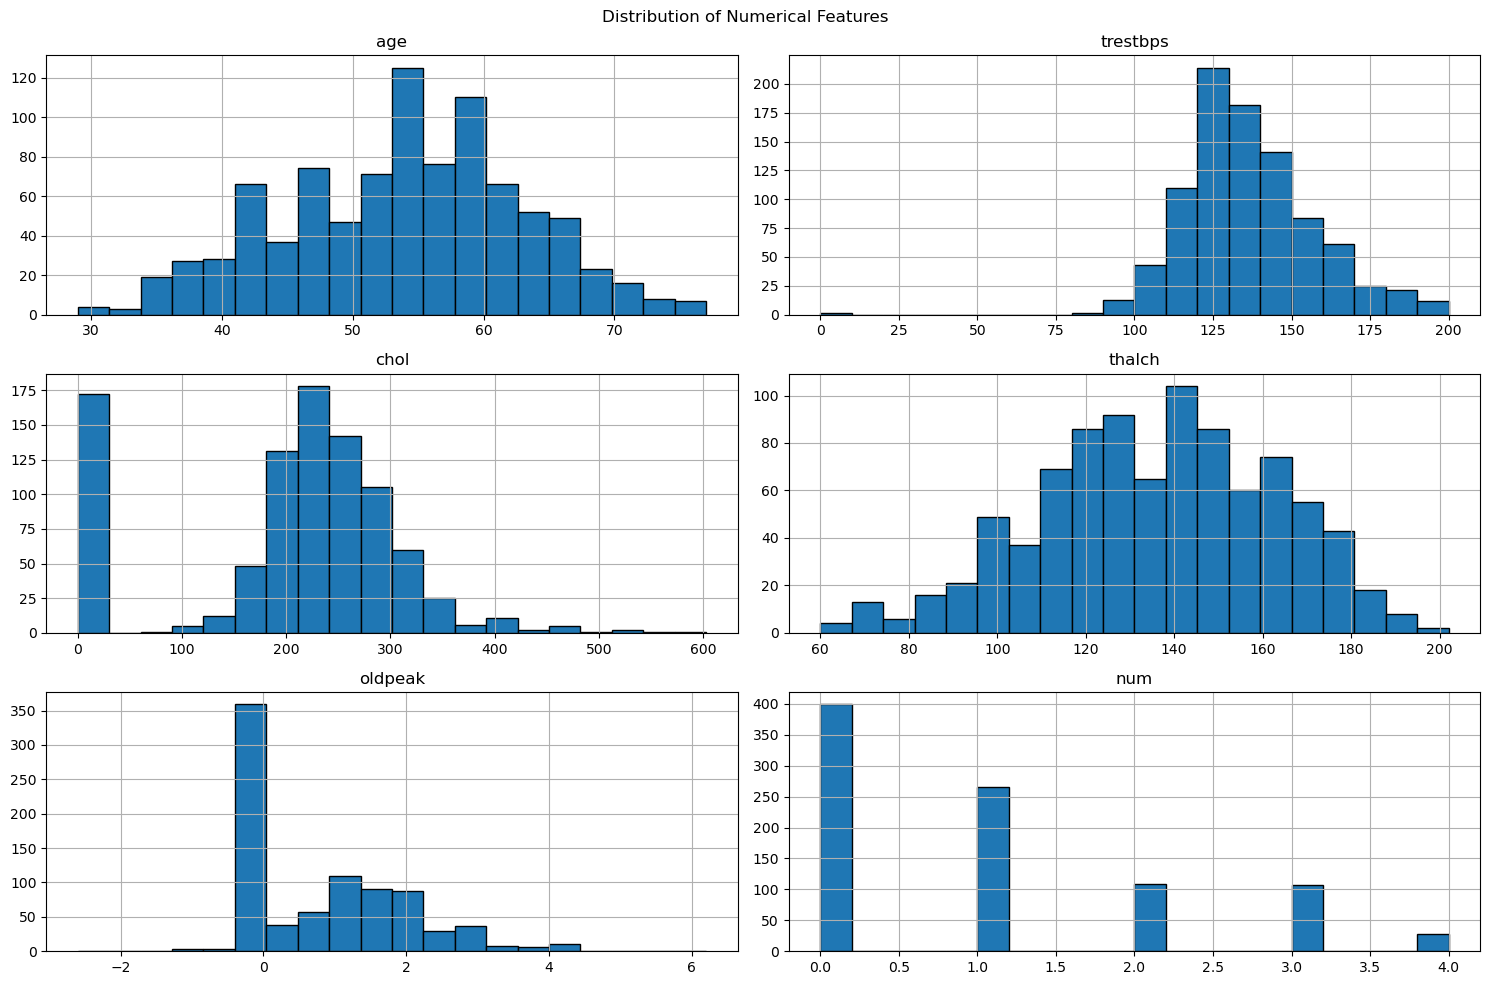

In [5]:
df[numerical_columns].hist(
    figsize=(15, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

4.3 Box plots – detect potential outliers

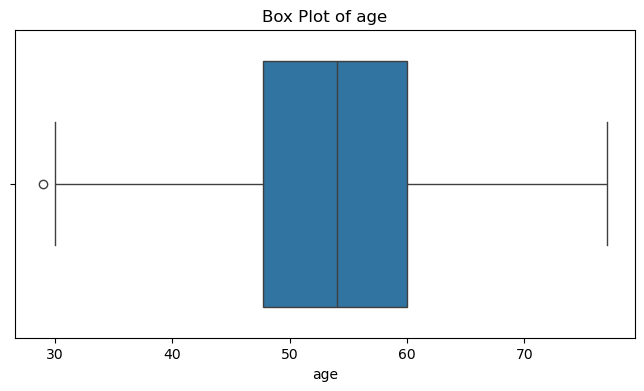

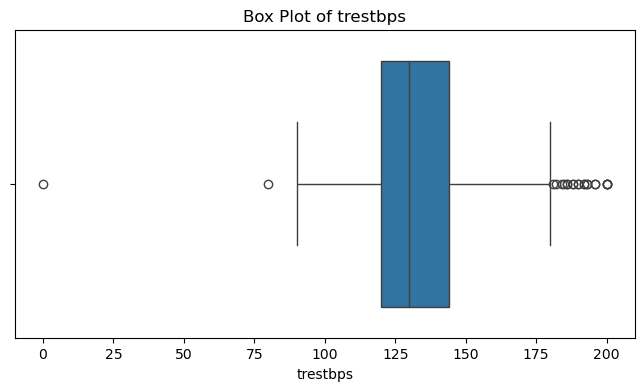

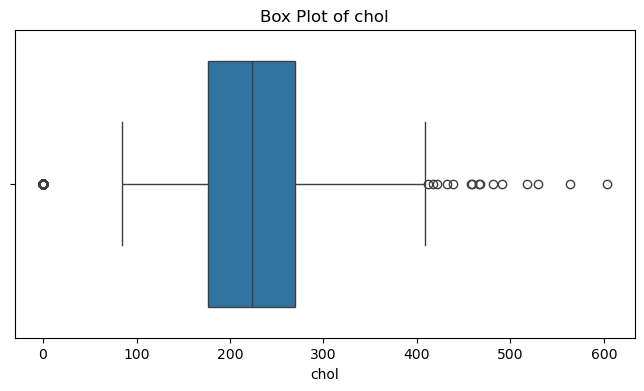

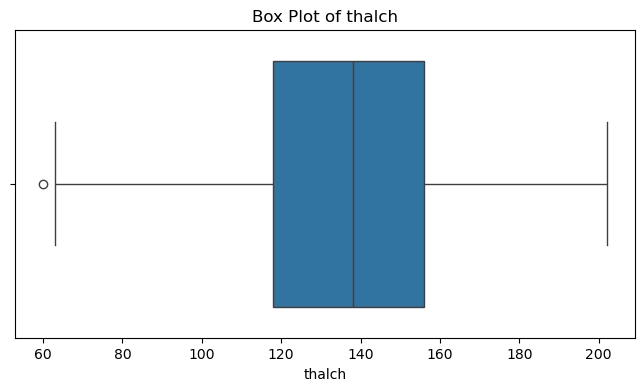

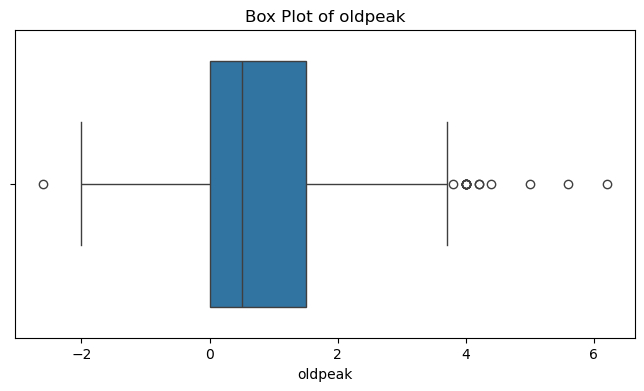

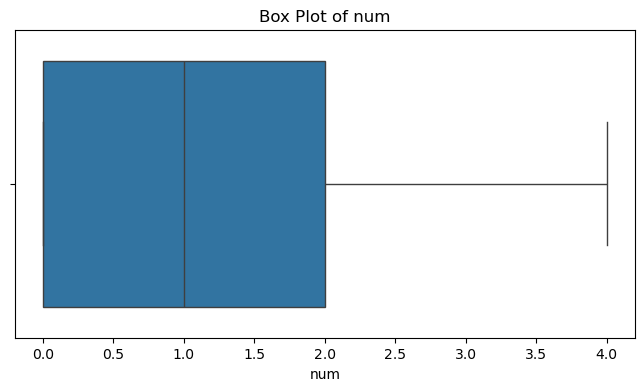

In [6]:
for column in numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[column])

    plt.title(f"Box Plot of {column}")
    plt.show()

4.4 Calculate outliers using the IQR method

In [7]:
for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ).sum()

    print(f"{column}: {outlier_count} potential outliers")

age: 1 potential outliers
trestbps: 22 potential outliers
chol: 187 potential outliers
thalch: 1 potential outliers
oldpeak: 16 potential outliers
num: 0 potential outliers


4.5 Correlation matrix

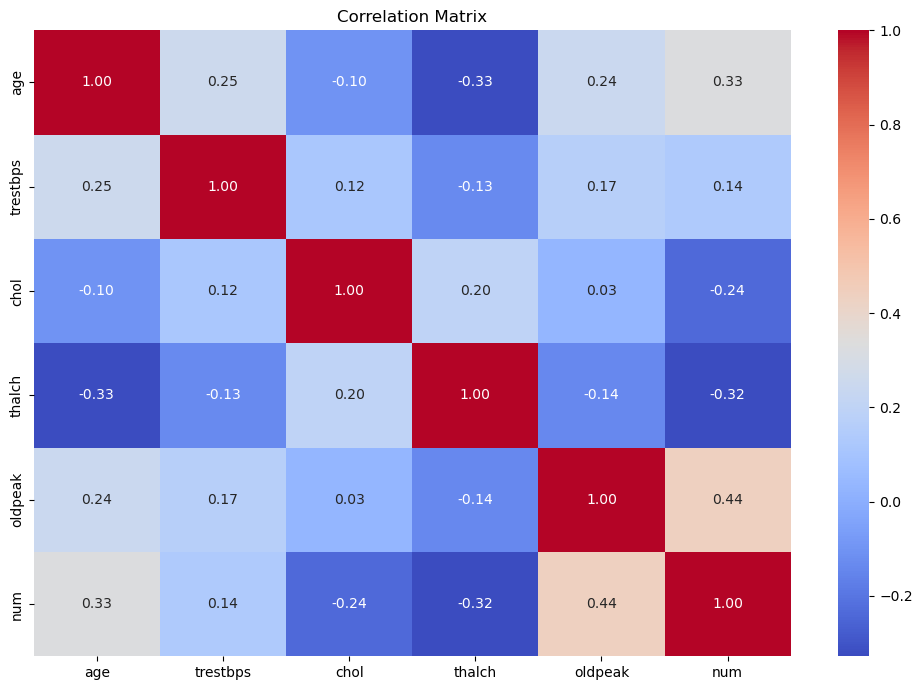

In [8]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df[numerical_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

5. Feature engineering – create the target

In [9]:
print("Original target distribution:")
print(df["num"].value_counts().sort_index())

Original target distribution:
num
0    399
1    265
2    109
3    107
4     28
Name: count, dtype: int64


In [10]:
# 0 = No heart disease
# 1, 2, 3, 4 = Heart disease

df["target"] = (df["num"] > 0).astype(int)

print("Binary target distribution:")
print(df["target"].value_counts().sort_index())

Binary target distribution:
target
0    399
1    509
Name: count, dtype: int64


In [11]:
print(pd.crosstab(df["num"], df["target"]))

target    0    1
num             
0       399    0
1         0  265
2         0  109
3         0  107
4         0   28


6. Separate features and target

In [12]:
# Input features
X = df.drop(columns=["num", "target"])

# Target variable
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Features shape: (908, 12)
Target shape: (908,)

Target classes:
target
1    509
0    399
Name: count, dtype: int64


7. Identify numerical and categorical features

In [13]:
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'trestbps', 'chol', 'thalch', 'oldpeak']

Categorical features:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


8. Preprocessing

In [14]:
X = X.copy()

for column in categorical_features:
    X[column] = X[column].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    )

In [15]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


9. Split the dataset into training and testing sets
Use an 80:20 split.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (726, 12)
Testing features: (182, 12)

Training target distribution:
target
1    407
0    319
Name: count, dtype: int64

Testing target distribution:
target
1    102
0     80
Name: count, dtype: int64


10. Build and train the Decision Tree model

In [17]:
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

In [18]:
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [19]:
y_pred = decision_tree_model.predict(X_test)

print("First 10 predicted values:")
print(y_pred[:10])

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

First 10 predicted values:
[0 0 1 1 1 0 0 1 0 1]

First 10 actual values:
[0 1 1 1 0 0 0 1 0 1]


11. Evaluate the original model

11.1 Calculate evaluation metrics

In [20]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("Decision Tree – Original Model")
print("--------------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))

Decision Tree – Original Model
--------------------------------
Accuracy : 0.6923
Precision: 0.717
Recall   : 0.7451
F1-score : 0.7308


11.2 Classification report

In [21]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Heart Disease", "Heart Disease"],
    zero_division=0
))

                  precision    recall  f1-score   support

No Heart Disease       0.66      0.62      0.64        80
   Heart Disease       0.72      0.75      0.73       102

        accuracy                           0.69       182
       macro avg       0.69      0.69      0.69       182
    weighted avg       0.69      0.69      0.69       182



11.3 Confusion matrix

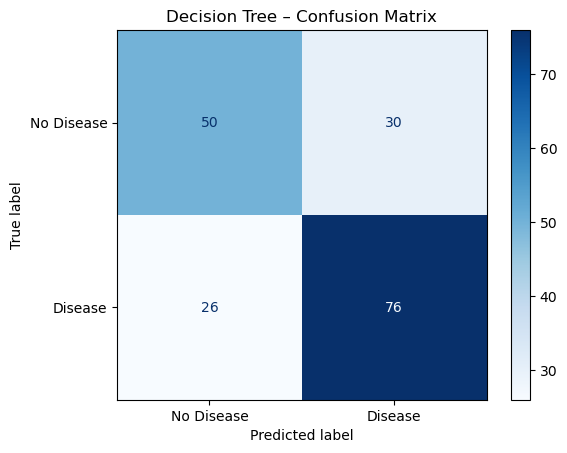

In [22]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Disease", "Disease"],
    cmap="Blues"
)

plt.title("Decision Tree – Confusion Matrix")
plt.show()

11.4 ROC-AUC score

In [23]:
y_probability = decision_tree_model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_probability)

print("ROC-AUC Score:", round(roc_auc, 4))

ROC-AUC Score: 0.685


12. Hyperparameter tuning using GridSearchCV

12.1 Define the parameter grid

In [24]:
parameter_grid = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [3, 5, 10, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 5]
}

12.2 Perform GridSearchCV

In [25]:
grid_search = GridSearchCV(
    estimator=decision_tree_model,
    param_grid=parameter_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Hyperparameter tuning completed!")

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Hyperparameter tuning completed!


12.3 Display the best parameters

In [26]:
print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(grid_search.best_score_, 4))

Best parameters:
{'classifier__criterion': 'gini', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10}

Best cross-validation F1-score:
0.7896


12.4 Get the optimized model

In [27]:
best_model = grid_search.best_estimator_

print("Optimized Decision Tree model ready!")

Optimized Decision Tree model ready!


13. Evaluate the optimized model

In [28]:
best_predictions = best_model.predict(X_test)

best_probability = best_model.predict_proba(X_test)[:, 1]

best_accuracy = accuracy_score(y_test, best_predictions)

best_precision = precision_score(
    y_test, best_predictions, zero_division=0
)

best_recall = recall_score(
    y_test, best_predictions, zero_division=0
)

best_f1 = f1_score(
    y_test, best_predictions, zero_division=0
)

best_roc_auc = roc_auc_score(y_test, best_probability)

print("Optimized Decision Tree Results")
print("--------------------------------")
print("Accuracy :", round(best_accuracy, 4))
print("Precision:", round(best_precision, 4))
print("Recall   :", round(best_recall, 4))
print("F1-score :", round(best_f1, 4))
print("ROC-AUC  :", round(best_roc_auc, 4))

Optimized Decision Tree Results
--------------------------------
Accuracy : 0.6923
Precision: 0.75
Recall   : 0.6765
F1-score : 0.7113
ROC-AUC  : 0.7564


13.1 Compare original and optimized models

In [29]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],

    "Original Model": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ],

    "Optimized Model": [
        best_accuracy,
        best_precision,
        best_recall,
        best_f1,
        best_roc_auc
    ]
})

display(comparison.round(4))

,Metric,Original Model,Optimized Model
0,Accuracy,0.6923,0.6923
1,Precision,0.7170,0.7500
2,Recall,0.7451,0.6765
3,F1-score,0.7308,0.7113
4,ROC-AUC,0.6850,0.7564


13.2 Optimized model confusion matrix

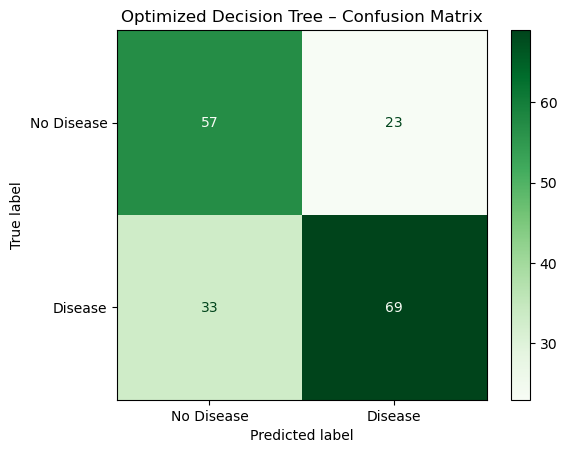

In [30]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=["No Disease", "Disease"],
    cmap="Greens"
)

plt.title("Optimized Decision Tree – Confusion Matrix")
plt.show()

14. Visualize the optimized Decision Tree

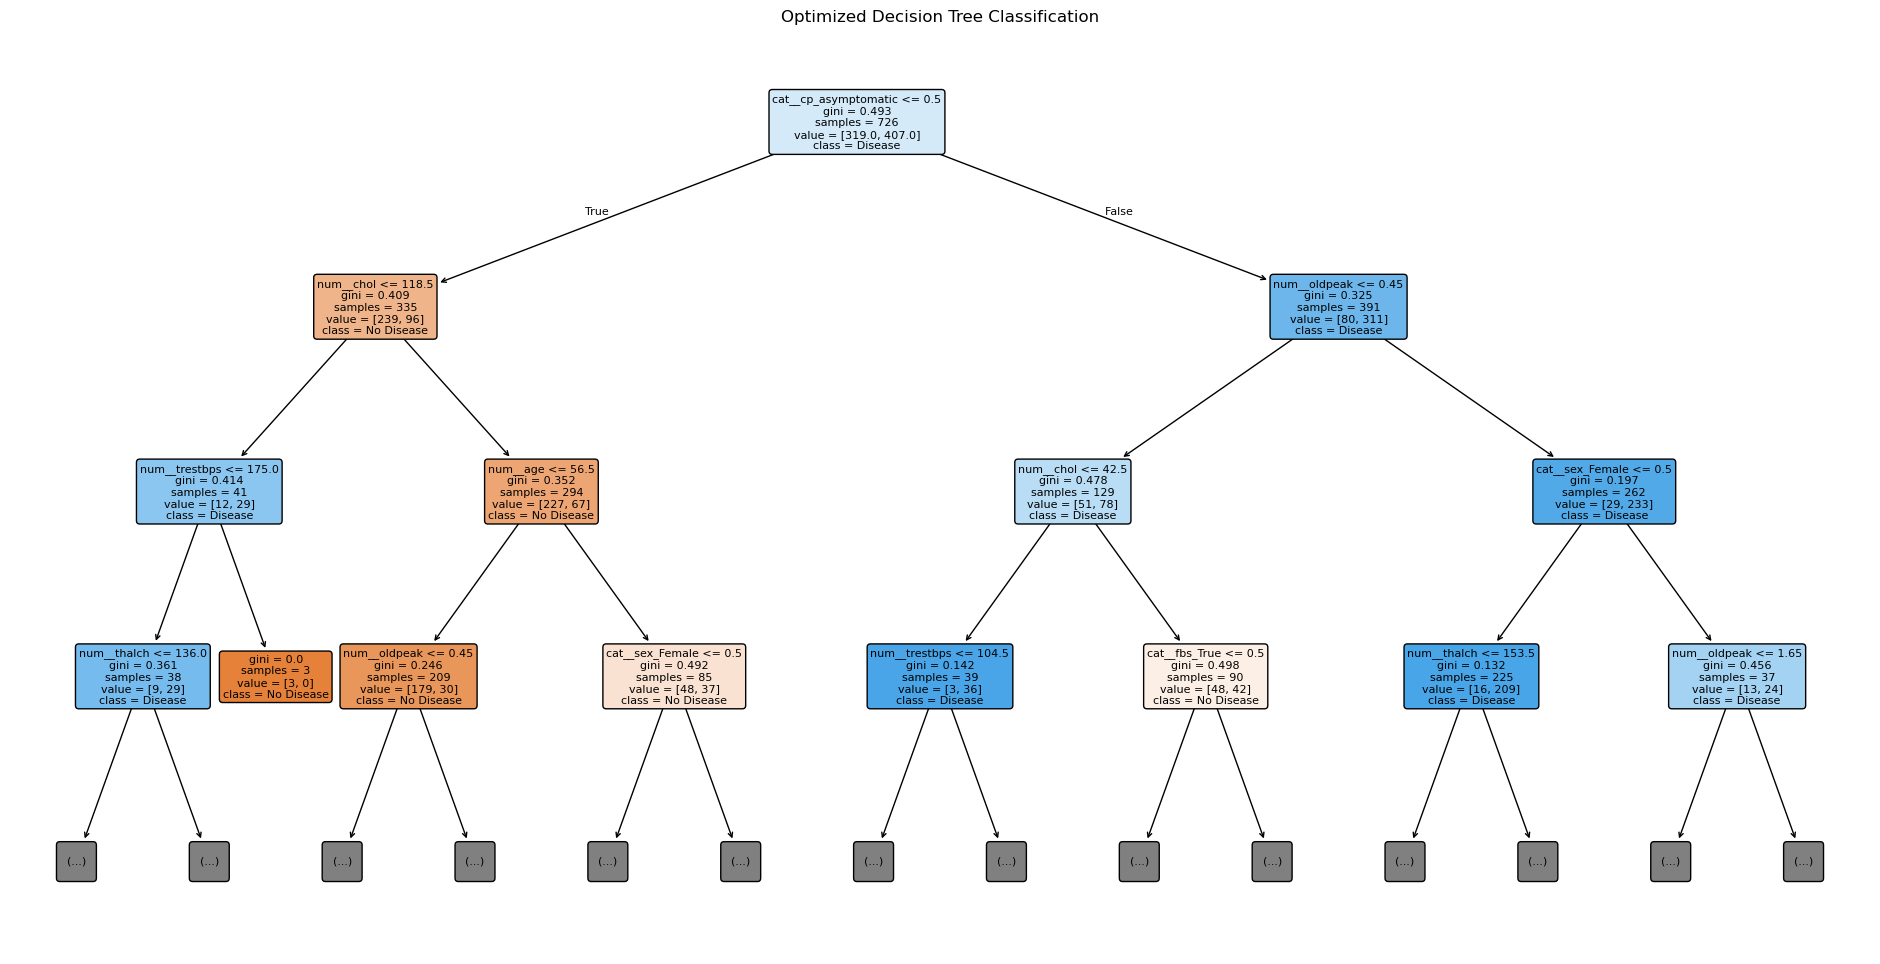

In [31]:
best_preprocessor = best_model.named_steps["preprocessor"]

feature_names = best_preprocessor.get_feature_names_out()

tree_classifier = best_model.named_steps["classifier"]

plt.figure(figsize=(24, 12))

plot_tree(
    tree_classifier,
    feature_names=feature_names,
    class_names=["No Disease", "Disease"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Optimized Decision Tree Classification")
plt.show()

15. Feature importance

In [32]:
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree_classifier.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
7,cat__cp_asymptomatic,0.453855
2,num__chol,0.175562
4,num__oldpeak,0.126866
0,num__age,0.080677
5,cat__sex_Female,0.050324
3,num__thalch,0.028206
22,cat__thal_normal,0.027917
1,num__trestbps,0.024231
12,cat__fbs_True,0.021261
14,cat__restecg_normal,0.009965


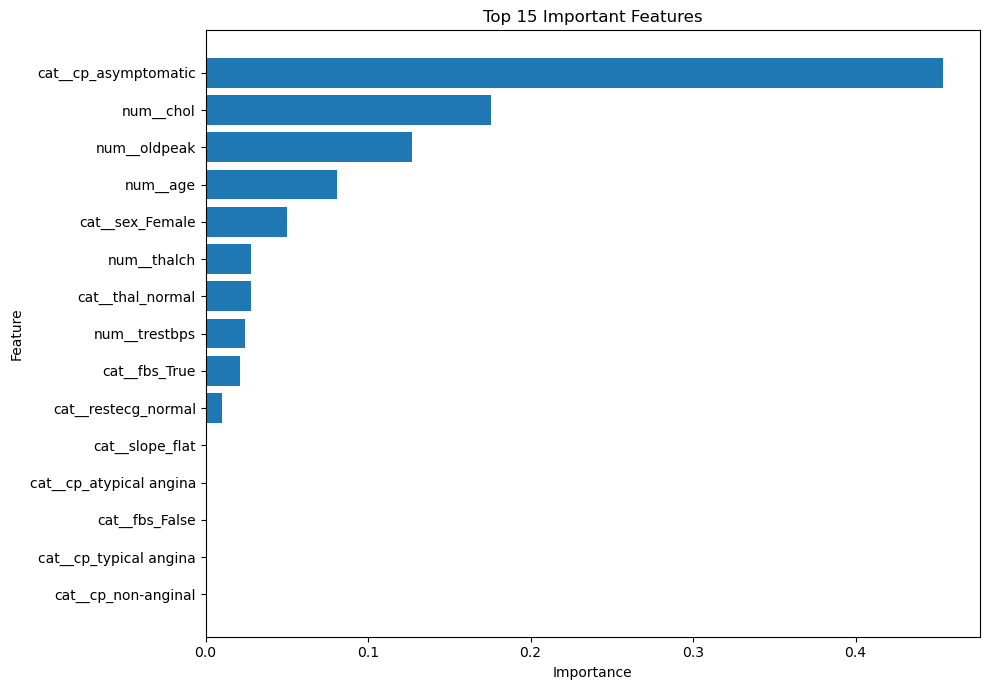

In [33]:
top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Important Features")

plt.tight_layout()
plt.show()